# Support Vector Machine - Drug Response Classification

The aim is to predict drug response using the patient's dosage and biomarker values. Here, 0 means no response and 1 means positive response.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

## Load the dataset

In [2]:
df = pd.read_csv("Pharma_Industry.csv")
df.head()

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
0,-0.128538,0.303280,-1.881849,0.258286,-0.792011,1
1,-1.846188,2.865142,-0.929511,2.866786,-0.719447,1
2,-1.252393,-1.541613,0.363632,-0.325370,0.191314,0
3,1.992515,-1.142779,-0.766657,0.975286,-0.823355,1
4,0.377100,0.538410,-0.029263,1.896015,-0.960130,1


In [3]:
df.shape

(500, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Drug Dosage (mg)                500 non-null    float64
 1   Systolic Blood Pressure (mmHg)  500 non-null    float64
 2   Heart Rate (BPM)                500 non-null    float64
 3   Liver Toxicity Index (U/L)      500 non-null    float64
 4   Blood Glucose Level (mg/dL)     500 non-null    float64
 5   Drug Response                   500 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 23.6 KB


In [5]:
df.isnull().sum()

Drug Dosage (mg)                  0
Systolic Blood Pressure (mmHg)    0
Heart Rate (BPM)                  0
Liver Toxicity Index (U/L)        0
Blood Glucose Level (mg/dL)       0
Drug Response                     0
dtype: int64

In [6]:
df.describe()

,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.0000
mean,-0.037761,0.214957,0.062871,0.054398,-0.171863,0.5200
std,0.979891,1.247567,0.971978,0.986001,0.983765,0.5001
min,-3.019512,-3.773897,-2.940389,-3.401277,-3.110431,0.0000
25%,-0.642003,-0.565168,-0.648157,-0.586085,-0.797715,0.0000
50%,-0.019340,0.201532,0.027732,-0.065661,-0.108106,1.0000
75%,0.641151,0.951375,0.710774,0.633914,0.513555,1.0000
max,2.949094,4.111751,3.193108,3.373269,2.518023,1.0000


## Explore the data

In [7]:
df["Drug Response"].value_counts()

Drug Response
1    260
0    240
Name: count, dtype: int64

In [8]:
df["Drug Response"].value_counts(normalize=True).round(3)

Drug Response
1    0.52
0    0.48
Name: proportion, dtype: float64

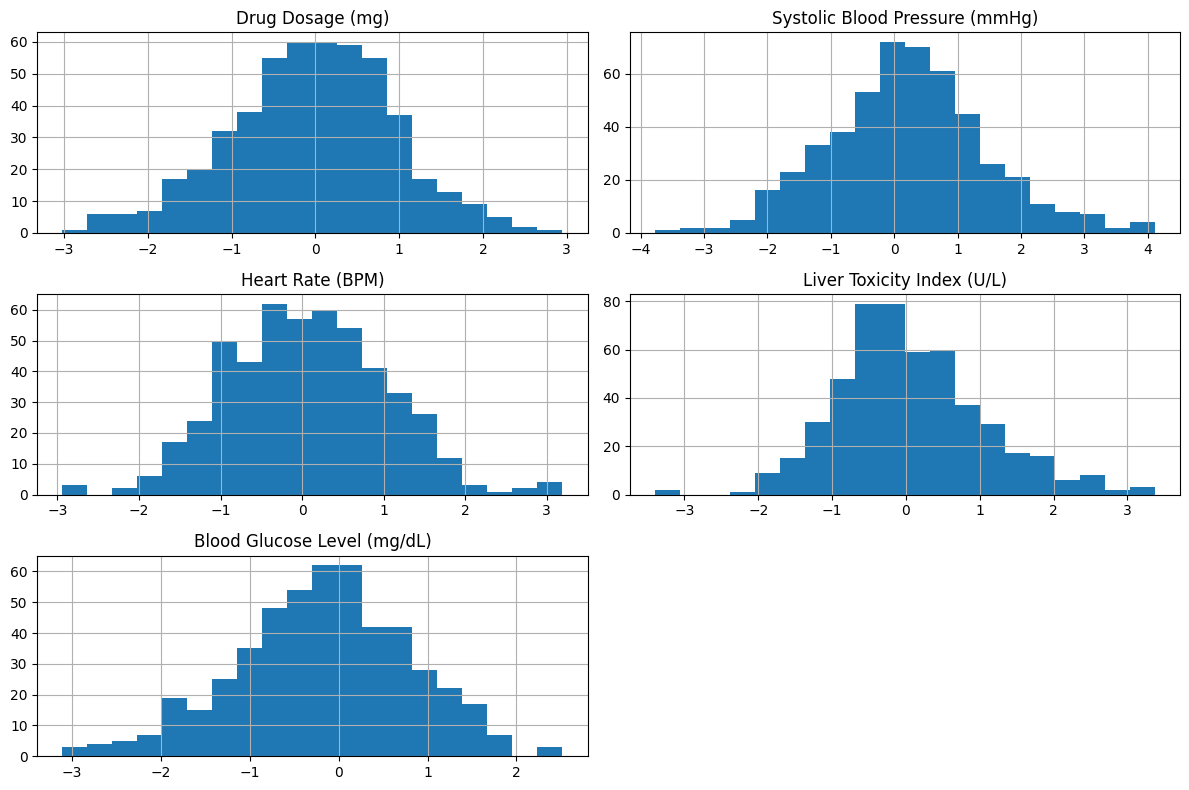

In [9]:
features = df.drop(columns=["Drug Response"]).columns

df[features].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

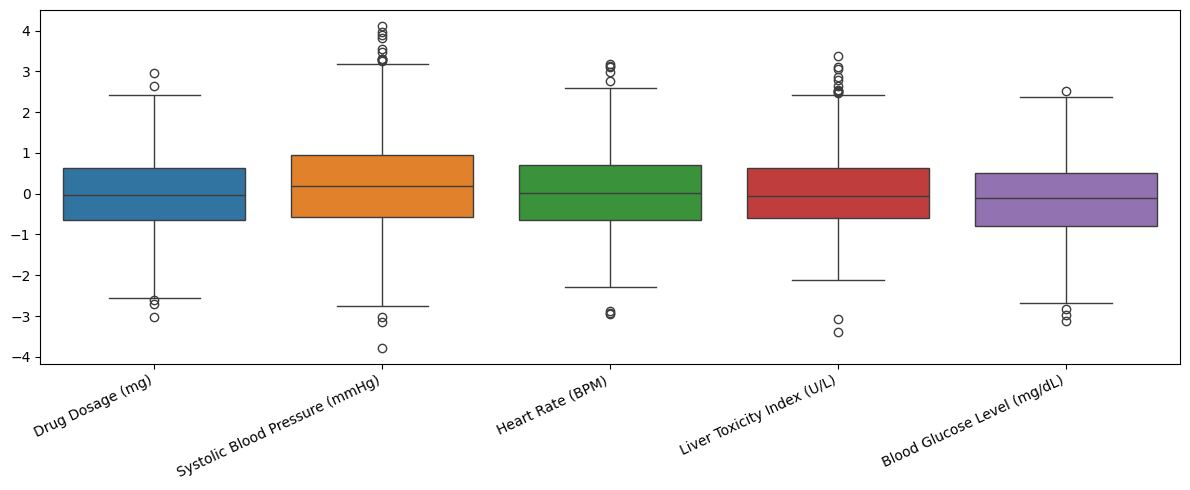

In [10]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[features])
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

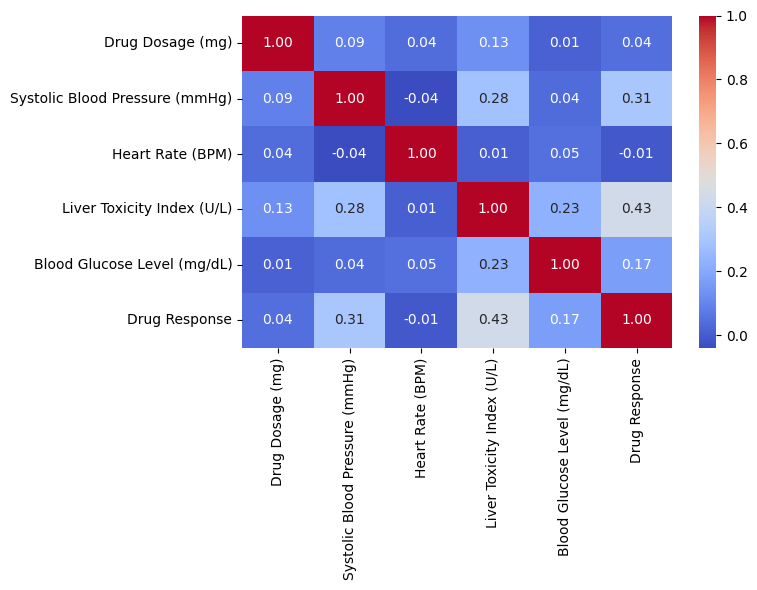

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.tight_layout()
plt.show()

All five input columns are numeric, so categorical encoding is not needed for this dataset.

## Visualize feature relationships

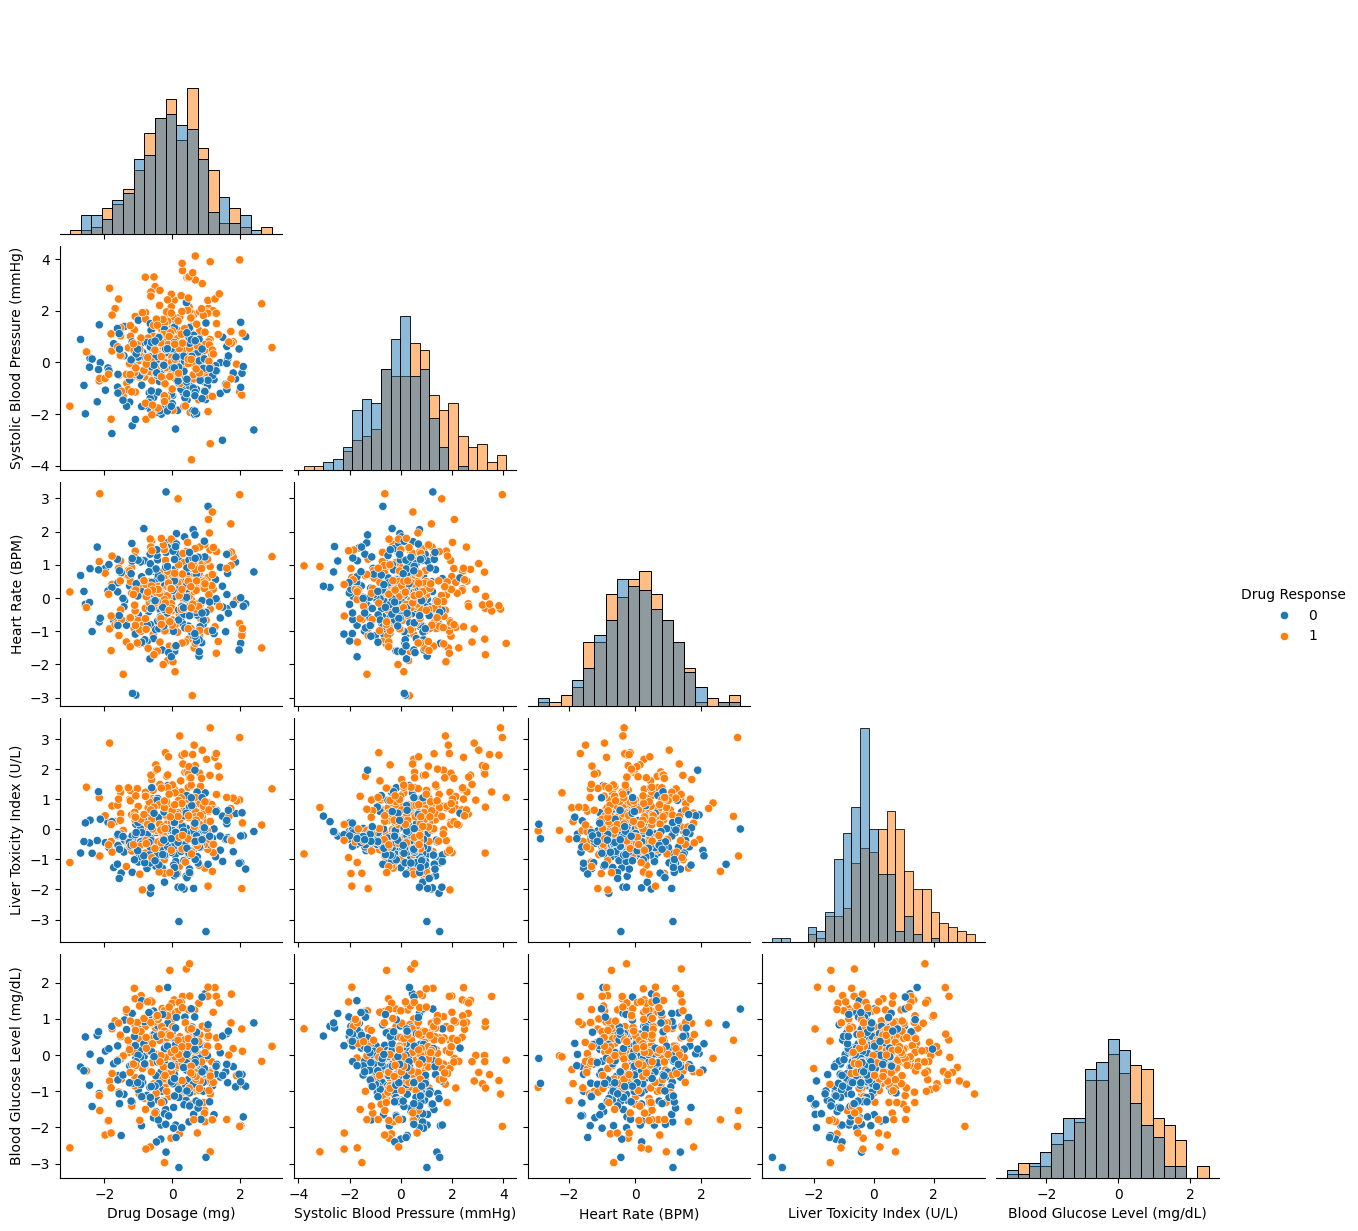

In [12]:
sns.pairplot(df, hue="Drug Response", diag_kind="hist", corner=True)
plt.show()

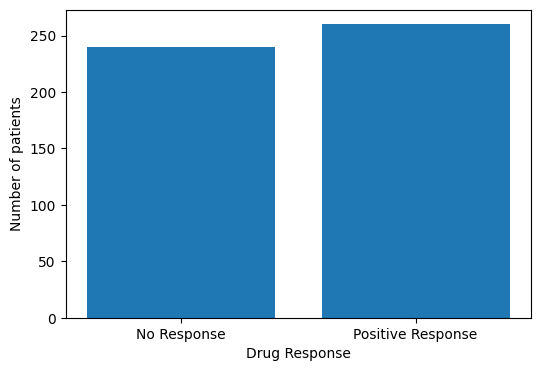

In [13]:
plt.figure(figsize=(6, 4))
counts = df["Drug Response"].value_counts().sort_index()
plt.bar(counts.index, counts.values)
plt.xticks([0, 1], ["No Response", "Positive Response"])
plt.xlabel("Drug Response")
plt.ylabel("Number of patients")
plt.show()

## Prepare training and testing data

In [14]:
X = df.drop(columns=["Drug Response"])
y = df["Drug Response"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 5)
Testing data: (100, 5)


## Train a basic SVM model

In [15]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", C=1))
])

svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))
print(classification_report(y_test, y_pred, target_names=["No Response", "Positive Response"], zero_division=0))

Accuracy: 0.77
Precision: 0.754
Recall: 0.827
F1-score: 0.789
                   precision    recall  f1-score   support

      No Response       0.79      0.71      0.75        48
Positive Response       0.75      0.83      0.79        52

         accuracy                           0.77       100
        macro avg       0.77      0.77      0.77       100
     weighted avg       0.77      0.77      0.77       100



## View the prediction results

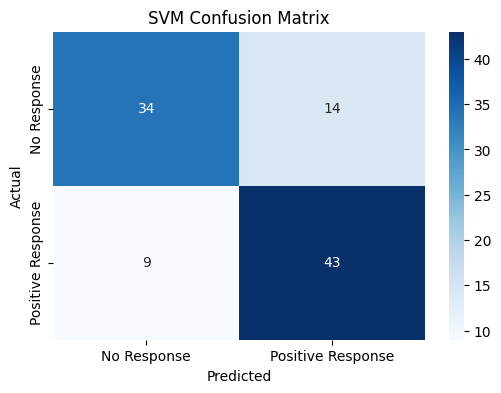

In [16]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Response", "Positive Response"],
    yticklabels=["No Response", "Positive Response"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()

In [17]:
results = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
results["Actual Label"] = results["Actual"].map({0: "No Response", 1: "Positive Response"})
results["Predicted Label"] = results["Predicted"].map({0: "No Response", 1: "Positive Response"})
results.head(10)

,Actual,Predicted,Actual Label,Predicted Label
0,1,1,Positive Response,Positive Response
1,0,1,No Response,Positive Response
2,1,1,Positive Response,Positive Response
3,0,0,No Response,No Response
4,0,0,No Response,No Response
5,1,1,Positive Response,Positive Response
6,0,1,No Response,Positive Response
7,0,0,No Response,No Response
8,1,1,Positive Response,Positive Response
9,1,1,Positive Response,Positive Response


## Compare SVM kernels

In [18]:
kernel_results = []

for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel=kernel, C=1))
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    kernel_results.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })

kernel_results = pd.DataFrame(kernel_results).sort_values("F1-score", ascending=False)
kernel_results.round(3)

,Kernel,Accuracy,Precision,Recall,F1-score
2,rbf,0.77,0.754,0.827,0.789
0,linear,0.72,0.761,0.673,0.714
1,poly,0.65,0.667,0.654,0.660


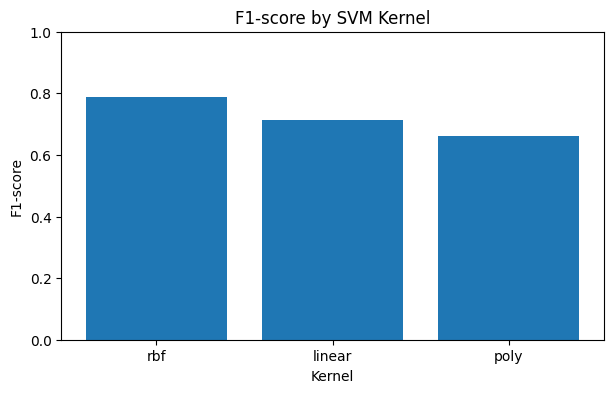

In [19]:
plt.figure(figsize=(7, 4))
plt.bar(kernel_results["Kernel"], kernel_results["F1-score"])
plt.ylim(0, 1)
plt.xlabel("Kernel")
plt.ylabel("F1-score")
plt.title("F1-score by SVM Kernel")
plt.show()

## Tune the model

In [20]:
param_grid = [
    {"model__kernel": ["linear"], "model__C": [0.1, 1, 10]},
    {"model__kernel": ["rbf"], "model__C": [0.1, 1, 10], "model__gamma": ["scale", "auto"]},
    {"model__kernel": ["poly"], "model__C": [0.1, 1, 10], "model__gamma": ["scale", "auto"], "model__degree": [2, 3]}
]

base_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

grid_search = GridSearchCV(base_model, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1-score:", round(grid_search.best_score_, 3))

Best parameters: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best cross-validation F1-score: 0.757


In [21]:
best_model = grid_search.best_estimator_
best_pred = best_model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, best_pred), 3))
print("Test precision:", round(precision_score(y_test, best_pred, zero_division=0), 3))
print("Test recall:", round(recall_score(y_test, best_pred, zero_division=0), 3))
print("Test F1-score:", round(f1_score(y_test, best_pred, zero_division=0), 3))
print(classification_report(y_test, best_pred, target_names=["No Response", "Positive Response"], zero_division=0))

Test accuracy: 0.75
Test precision: 0.745
Test recall: 0.788
Test F1-score: 0.766
                   precision    recall  f1-score   support

      No Response       0.76      0.71      0.73        48
Positive Response       0.75      0.79      0.77        52

         accuracy                           0.75       100
        macro avg       0.75      0.75      0.75       100
     weighted avg       0.75      0.75      0.75       100



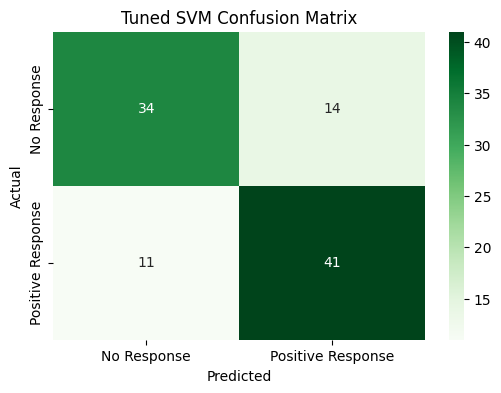

In [22]:
best_cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    best_cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=["No Response", "Positive Response"],
    yticklabels=["No Response", "Positive Response"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned SVM Confusion Matrix")
plt.show()

## Analysis

In [24]:
print("Kernel comparison:")
display(kernel_results.round(3))


Kernel comparison:


,Kernel,Accuracy,Precision,Recall,F1-score
2,rbf,0.77,0.754,0.827,0.789
0,linear,0.72,0.761,0.673,0.714
1,poly,0.65,0.667,0.654,0.660
